# Loan Delinquency Risk Analysis

### Business Context

DRS Bank has observed a steady rise in Non-Performing Assets (NPAs), a significant portion of which stems from loans extended to individual borrowers. To curb further deterioration of the loan portfolio, the Chief Risk Officer has mandated the data-science team to design a data-driven credit-approval framework that minimises the probability of a loan becoming delinquent.

### Objective

Identify the key borrower and loan attributes that drive delinquency and build predictive models (including bagging and boosting ensembles with hyper-parameter tuning) that can flag high-risk applications before approval.

### Guiding Questions
- Which factors most strongly influence loan delinquency?
- How can the bank set approval criteria that keep delinquency risk within acceptable limits?

### Data Dictionary

| Column | Description |
|--------|-------------|
| ID | Unique customer identifier |
| isDelinquent | Target – 1 if the customer is delinquent, 0 otherwise |
| term | Loan tenure (36 months / 60 months) |
| gender | Gender of the borrower |
| age | Age band of the borrower (20-25 / >25) |
| purpose | Stated purpose of the loan |
| home_ownership | Housing status (Mortgage / Rent / Own) |
| FICO | Bureau score band (300-500 / >500) |

### Domain Notes
- **Transactor** – pays the full outstanding balance on time every month.
- **Revolver** – pays only the minimum due and carries a revolving balance.
- **Delinquent** – has missed the minimum payment.
- **Defaulter** – remains delinquent beyond a contractual threshold and is declared in default.

## Importing Libraries

In [33]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    f1_score, accuracy_score, recall_score, precision_score,
    confusion_matrix, roc_auc_score, classification_report
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier, RandomForestClassifier,
    GradientBoostingClassifier, AdaBoostClassifier, StackingClassifier
)

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from xgboost import XGBClassifier

import scipy.stats as stats

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: "%.3f" % x)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

## Loading the Data

In [34]:
data = pd.read_csv("Loan_Delinquent_Dataset.csv")
print("Dataset shape:", data.shape)
data.head()

Dataset shape: (11548, 8)


,ID,isDelinquent,term,gender,purpose,home_ownership,age,FICO
0,1,1,36 months,Female,House,Mortgage,>25,300-500
1,2,0,36 months,Female,House,Rent,20-25,>500
2,3,1,36 months,Female,House,Rent,>25,300-500
3,4,1,36 months,Female,Car,Mortgage,>25,300-500
4,5,1,36 months,Female,House,Rent,>25,300-500


## Data Overview

In [35]:
loan = data.copy()
loan.tail()

,ID,isDelinquent,term,gender,purpose,home_ownership,age,FICO
11543,11544,0,60 months,Male,other,Mortgage,>25,300-500
11544,11545,1,36 months,Male,House,Rent,20-25,300-500
11545,11546,0,36 months,Female,Personal,Mortgage,20-25,>500
11546,11547,1,36 months,Female,House,Rent,20-25,300-500
11547,11548,1,36 months,Male,Personal,Mortgage,20-25,300-500


In [36]:
loan.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11548 entries, 0 to 11547
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   ID              11548 non-null  int64 
 1   isDelinquent    11548 non-null  int64 
 2   term            11548 non-null  object
 3   gender          11548 non-null  object
 4   purpose         11548 non-null  object
 5   home_ownership  11548 non-null  object
 6   age             11548 non-null  object
 7   FICO            11548 non-null  object
dtypes: int64(2), object(6)
memory usage: 721.9+ KB


**Pin-point observations**
- The dataset contains 11 548 rows and 8 columns.
- All features except ID are currently stored as object / int64; several should be converted to category for efficiency.

## Fixing Data Types

In [37]:
cat_cols = ["term", "gender", "purpose", "home_ownership", "age", "FICO"]
for col in cat_cols:
    loan[col] = loan[col].astype("category")

loan.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11548 entries, 0 to 11547
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   ID              11548 non-null  int64   
 1   isDelinquent    11548 non-null  int64   
 2   term            11548 non-null  category
 3   gender          11548 non-null  category
 4   purpose         11548 non-null  category
 5   home_ownership  11548 non-null  category
 6   age             11548 non-null  category
 7   FICO            11548 non-null  category
dtypes: category(6), int64(2)
memory usage: 249.2 KB


**Pin-point observations**
- Converting the six categorical columns reduced memory footprint substantially.
- All predictors are now categorical; the target remains numeric (0/1).

In [38]:
print("Duplicate rows:", loan.duplicated().sum())
print("\nMissing values:")
print(loan.isnull().sum())

Duplicate rows: 0

Missing values:
ID                0
isDelinquent      0
term              0
gender            0
purpose           0
home_ownership    0
age               0
FICO              0
dtype: int64


**Pin-point observations**
- No duplicate records and no missing values – the data is clean.

In [39]:
loan.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,11548.000,NaN,NaN,NaN,5774.500,3333.765,1.000,2887.750,5774.500,8661.250,11548.000
isDelinquent,11548.000,NaN,NaN,NaN,0.669,0.471,0.000,0.000,1.000,1.000,1.000
term,11548,2,36 months,10589,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,11548,2,Male,6555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
purpose,11548,7,House,6892,NaN,NaN,NaN,NaN,NaN,NaN,NaN
home_ownership,11548,3,Mortgage,5461,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,11548,2,20-25,5888,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FICO,11548,2,300-500,6370,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Pin-point observations**
- Roughly two-thirds of customers are flagged as delinquent.
- The majority of loans are 36-month term loans.
- Female applicants slightly outnumber male applicants.
- House is the most common loan purpose.
- Most borrowers either rent or hold a mortgage; very few own their home outright.
- Age bands 20-25 and >25 are almost equally represented.
- A slight majority of applicants have a FICO score in the 300-500 band.

## Data Pre-Processing

In [40]:
print("Unique IDs:", loan["ID"].nunique())
loan.drop(columns=["ID"], inplace=True)

Unique IDs: 11548


**Pin-point observations**
- Every ID is unique, so the column carries no predictive information and is dropped.

In [41]:
print("Purpose values before cleaning:")
print(loan["purpose"].unique())

# Harmonise casing of the 'other' category
loan["purpose"] = loan["purpose"].replace({"other": "Other"})

print("\nPurpose values after cleaning:")
print(loan["purpose"].unique())

Purpose values before cleaning:
['House', 'Car', 'Other', 'Personal', 'Wedding', 'Medical', 'other']
Categories (7, object): ['Car', 'House', 'Medical', 'Other', 'Personal', 'Wedding', 'other']

Purpose values after cleaning:
['House', 'Car', 'Other', 'Personal', 'Wedding', 'Medical']
Categories (6, object): ['Car', 'House', 'Medical', 'Other', 'Personal', 'Wedding']


**Pin-point observations**
- Two spellings of the same category (‘other’ / ‘Other’) have been merged into a single level.

## Exploratory Data Analysis

### Helper – Labeled Bar Plot

In [42]:
def labeled_barplot(data, feature, perc=False, n=None):
    """Bar-plot with percentage or count labels on top of each bar."""
    total = len(data[feature])
    count = data[feature].nunique()
    if n is None:
        plt.figure(figsize=(count + 1, 5))
    else:
        plt.figure(figsize=(n + 1, 5))

    ax = sns.countplot(
        data=data, x=feature,
        palette="Paired",
        order=data[feature].value_counts().index[:n].sort_values()
    )

    for p in ax.patches:
        if perc:
            label = "{:.1f}%".format(100 * p.get_height() / total)
        else:
            label = p.get_height()
        x = p.get_x() + p.get_width() / 2
        y = p.get_height()
        ax.annotate(label, (x, y), ha="center", va="bottom", fontsize=10, xytext=(0, 3), textcoords="offset points")

    plt.show()

### Target Variable – isDelinquent

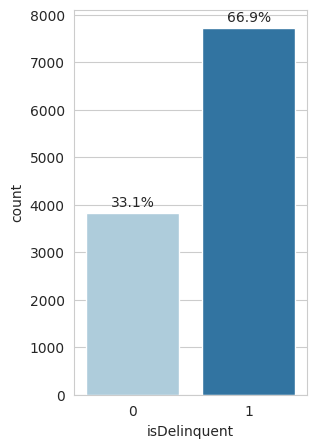

In [43]:
labeled_barplot(loan, "isDelinquent", perc=True)

**Pin-point observations**
- Approximately 66 % of the customers in the sample are delinquent.
- The class imbalance is moderate; oversampling / undersampling will be examined later.

### Loan Term

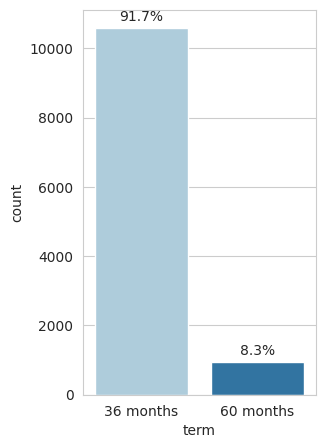

In [44]:
labeled_barplot(loan, "term", perc=True)

**Pin-point observations**
- 91.7 % of loans are 36-month contracts; only 8.3 % are 60-month contracts.

### Gender

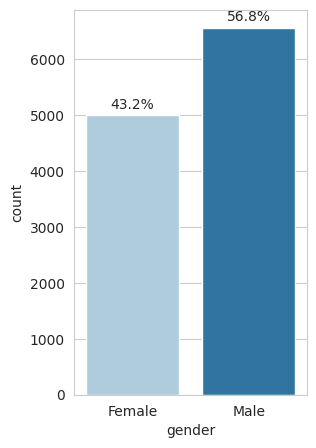

In [45]:
labeled_barplot(loan, "gender", perc=True)

**Pin-point observations**
- Female applicants constitute roughly 55 % of the portfolio; males 45 %.

### Loan Purpose

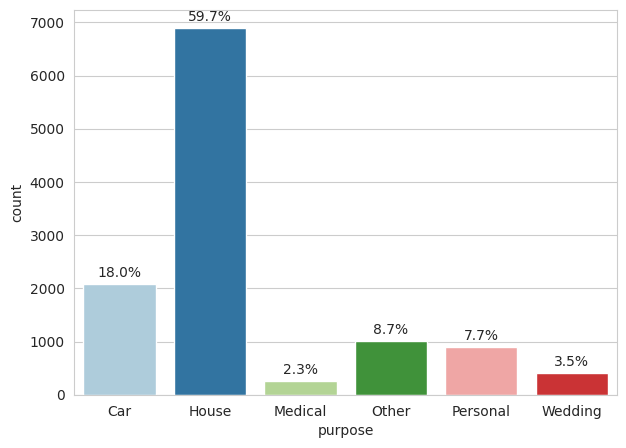

In [46]:
labeled_barplot(loan, "purpose", perc=True)

**Pin-point observations**
- House loans dominate (≈ 55 %).
- Car and Personal loans form the next largest groups.
- Medical, Wedding and Other purposes are relatively rare.

### Home Ownership

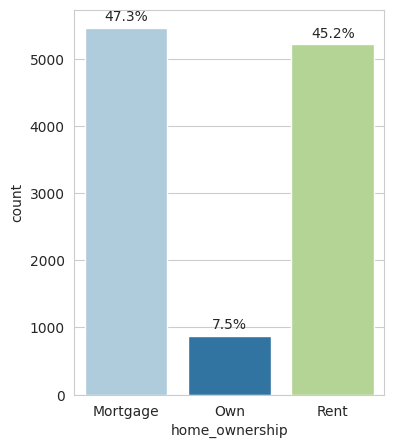

In [47]:
labeled_barplot(loan, "home_ownership", perc=True)

**Pin-point observations**
- Fewer than 10 % of applicants own their home outright.
- The majority either rent or have an existing mortgage.

### Age Band

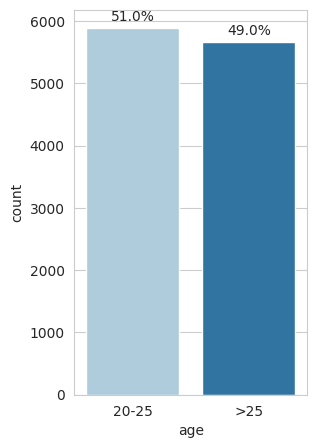

In [48]:
labeled_barplot(loan, "age", perc=True)

**Pin-point observations**
- The two age bands (20-25 and >25) are almost equally represented in the data.

### FICO Score Band

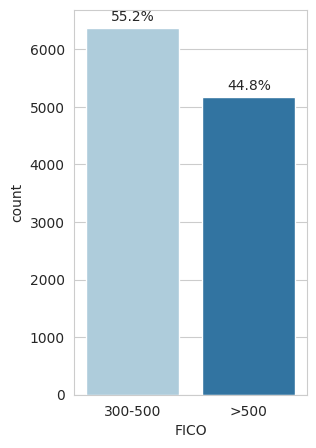

In [49]:
labeled_barplot(loan, "FICO", perc=True)

**Pin-point observations**
- 55 % of customers fall in the lower FICO band (300-500).
- 45 % have a score above 500.

### Helper – Stacked Bar Plot

In [50]:
def stacked_barplot(data, predictor, target):
    """Stacked percentage bar-plot of target versus a categorical predictor."""
    count = data[predictor].nunique()
    sorter = data[target].value_counts().index[-1]
    tab = pd.crosstab(data[predictor], data[target], normalize="index").sort_values(
        by=sorter, ascending=False
    )
    tab.plot(kind="bar", stacked=True, figsize=(count + 3, 5))
    plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
    plt.show()

### Delinquency by Loan Term

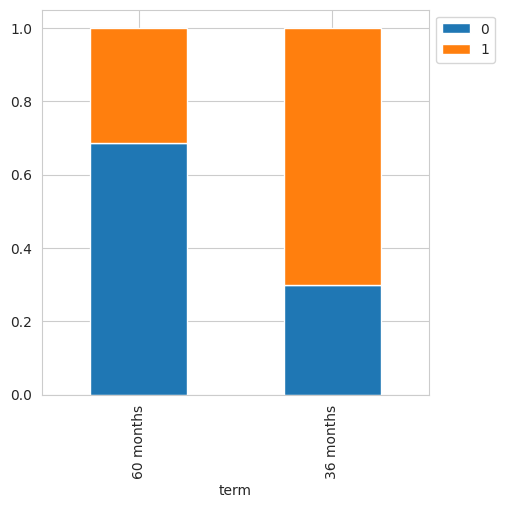

In [51]:
stacked_barplot(loan, "term", "isDelinquent")

**Pin-point observations**
- Delinquency is markedly higher among 36-month loans.
- 60-month loans show a substantially lower delinquency rate.

### Delinquency by Gender

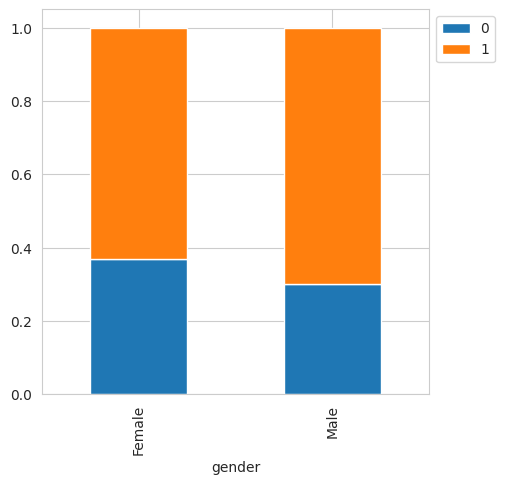

In [52]:
stacked_barplot(loan, "gender", "isDelinquent")

**Pin-point observations**
- Male borrowers exhibit a modestly higher delinquency rate than female borrowers.

### Delinquency by Loan Purpose

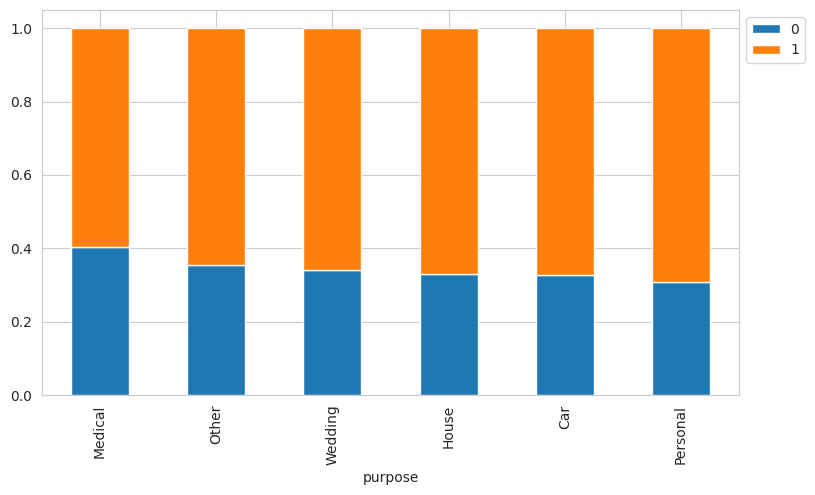

In [53]:
stacked_barplot(loan, "purpose", "isDelinquent")

**Pin-point observations**
- House and Medical loans show the highest proportions of delinquent customers.
- Car and Other purposes have comparatively lower delinquency shares.

### Delinquency by Home Ownership

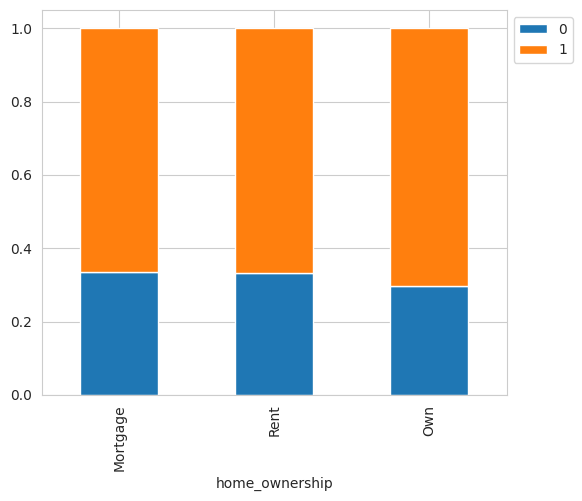

In [54]:
stacked_barplot(loan, "home_ownership", "isDelinquent")

**Pin-point observations**
- Borrowers who own their home outright display the lowest delinquency rate.
- Renters and mortgage-holders show higher (and similar) delinquency levels.

### Delinquency by Age Band

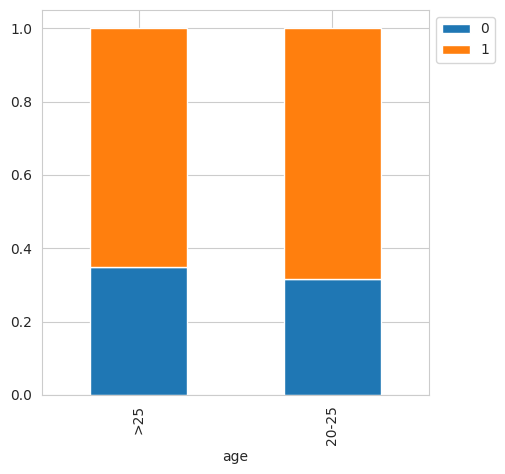

In [55]:
stacked_barplot(loan, "age", "isDelinquent")

**Pin-point observations**
- Applicants aged 20-25 have a higher delinquency rate than those older than 25.

### Delinquency by FICO Band

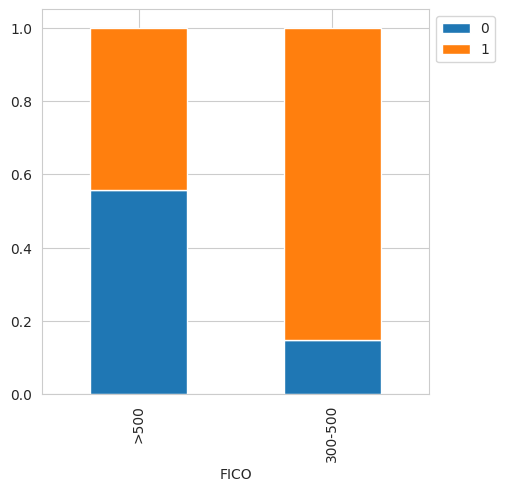

In [56]:
stacked_barplot(loan, "FICO", "isDelinquent")

**Pin-point observations**
- A FICO score above 500 is associated with a sharp drop in delinquency.
- The 300-500 band carries a markedly higher risk.

### Key EDA Take-aways

- **FICO score** and **loan term** emerge as the strongest univariate drivers of delinquency.
- Gender, age and home-ownership show milder but still visible associations.
- House-purpose loans contribute a large absolute number of delinquent accounts simply because they dominate the portfolio.

### Relationship of FICO with Other Attributes

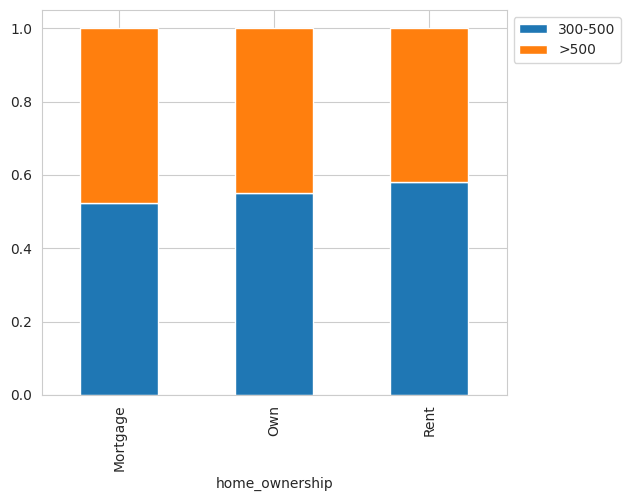

In [57]:
stacked_barplot(loan, "home_ownership", "FICO")

**Pin-point observations**
- Home owners are more likely to fall into the >500 FICO band than renters or mortgage-holders.

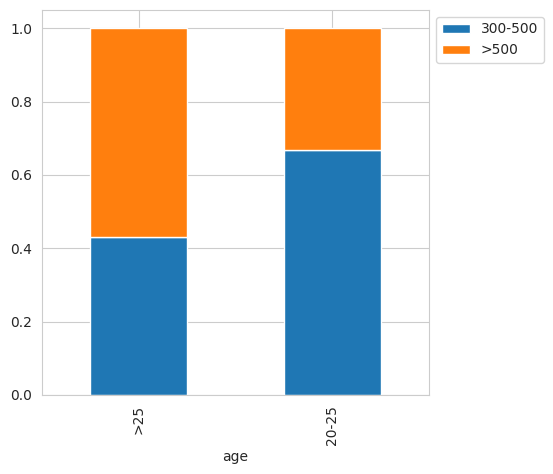

In [58]:
stacked_barplot(loan, "age", "FICO")

**Pin-point observations**
- The older age band (>25) contains a higher share of applicants with FICO >500.

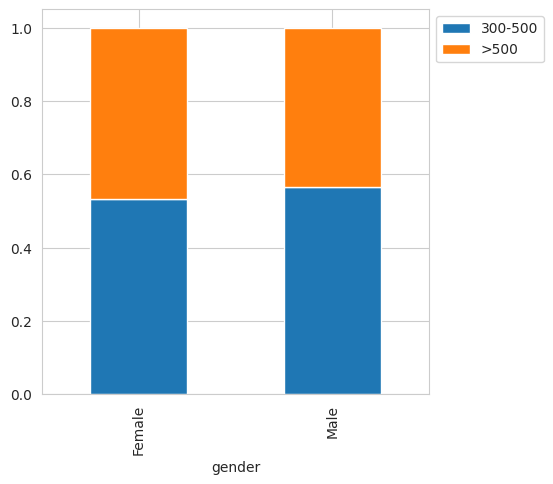

In [59]:
stacked_barplot(loan, "gender", "FICO")

**Pin-point observations**
- Female applicants are slightly more likely to have a FICO score above 500.

### Statistical Significance Tests (Chi-square)

In [60]:
def chi_square_test(data, col1, col2):
    """Perform chi-square test of independence and print the p-value."""
    crosstab = pd.crosstab(data[col1], data[col2])
    chi2, p, dof, expected = stats.chi2_contingency(crosstab)
    print(f"Chi-square test between {col1} and {col2}")
    print(f"  p-value = {p:.4e}")
    if p < 0.05:
        print("  → Difference is statistically significant.\n")
    else:
        print("  → Difference is NOT statistically significant.\n")

In [61]:
chi_square_test(loan, "FICO", "home_ownership")
chi_square_test(loan, "FICO", "gender")
chi_square_test(loan, "FICO", "age")

Chi-square test between FICO and home_ownership
  p-value = 1.0827e-08
  → Difference is statistically significant.

Chi-square test between FICO and gender
  p-value = 8.0851e-04
  → Difference is statistically significant.

Chi-square test between FICO and age
  p-value = 2.4923e-142
  → Difference is statistically significant.



**Pin-point observations**
- All three chi-square tests yield p-values well below 0.01, confirming that the observed differences in FICO distribution across home-ownership, gender and age are statistically significant.

## Data Preparation for Modelling

In [62]:
X = loan.drop(columns=["isDelinquent"])
y = loan["isDelinquent"]

# One-hot encode categorical predictors
X = pd.get_dummies(X, drop_first=True)

print("Feature matrix shape:", X.shape)
X.head()

Feature matrix shape: (11548, 11)


,term_60 months,gender_Male,purpose_House,purpose_Medical,purpose_Other,purpose_Personal,purpose_Wedding,home_ownership_Own,home_ownership_Rent,age_>25,FICO_>500
0,False,False,True,False,False,False,False,False,False,True,False
1,False,False,True,False,False,False,False,False,True,False,True
2,False,False,True,False,False,False,False,False,True,True,False
3,False,False,False,False,False,False,False,False,False,True,False
4,False,False,True,False,False,False,False,False,True,True,False


In [63]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=1, stratify=y
)

print("Train shape:", X_train.shape)
print("Test shape :", X_test.shape)
print("\nClass balance – Train:")
print(y_train.value_counts(normalize=True))

Train shape: (8083, 11)
Test shape : (3465, 11)

Class balance – Train:
isDelinquent
1   0.669
0   0.331
Name: proportion, dtype: float64


In [65]:
from imblearn.over_sampling import SMOTE
import pandas as pd

# Convert Boolean columns to integers (True = 1, False = 0)
X_train = X_train.copy()
X_train = X_train.astype({
    col: 'int64'
    for col in X_train.select_dtypes(include=['bool']).columns
})

# Apply SMOTE
smote = SMOTE(random_state=1)

X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("After SMOTE:")
print(pd.Series(y_train_smote).value_counts())

After SMOTE:
isDelinquent
1    5404
0    5404
Name: count, dtype: int64


## Handling Class Imbalance

In [66]:
# SMOTE oversampling (applied only on training data)
smote = SMOTE(random_state=1)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
print("After SMOTE:")
print(pd.Series(y_train_smote).value_counts())

After SMOTE:
isDelinquent
1    5404
0    5404
Name: count, dtype: int64


In [67]:
# Random under-sampling (for comparison)
rus = RandomUnderSampler(random_state=1)
X_train_rus, y_train_rus = rus.fit_resample(X_train, y_train)
print("After RandomUnderSampler:")
print(pd.Series(y_train_rus).value_counts())

After RandomUnderSampler:
isDelinquent
0    2679
1    2679
Name: count, dtype: int64


**Pin-point observations**
- SMOTE balances the minority (non-delinquent) class by generating synthetic examples.
- Random under-sampling reduces the majority class to match the minority class size.
- Main models will be trained on the SMOTE-balanced set; the original test set is left untouched.

## Model Building

In [68]:
def model_performance(model, X_train, y_train, X_test, y_test, name="Model"):
    """Fit model and return a dictionary of train/test metrics."""
    model.fit(X_train, y_train)
    y_pred_tr = model.predict(X_train)
    y_pred_te = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
        auc = roc_auc_score(y_test, y_prob)
    else:
        auc = np.nan

    return {
        "Model": name,
        "Train Acc": accuracy_score(y_train, y_pred_tr),
        "Test Acc" : accuracy_score(y_test, y_pred_te),
        "Precision": precision_score(y_test, y_pred_te),
        "Recall"   : recall_score(y_test, y_pred_te),
        "F1"       : f1_score(y_test, y_pred_te),
        "ROC-AUC"  : auc
    }, model

### 1. Logistic Regression (Baseline)

In [69]:
lr = LogisticRegression(random_state=1, max_iter=1000)
lr_metrics, lr_fitted = model_performance(
    lr, X_train_smote, y_train_smote, X_test, y_test, "Logistic Regression"
)
pd.DataFrame([lr_metrics])

,Model,Train Acc,Test Acc,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.797,0.784,0.882,0.781,0.829,0.827


### 2. Decision Tree (Baseline)

In [70]:
dt = DecisionTreeClassifier(random_state=1, class_weight="balanced")
dt_metrics, dt_fitted = model_performance(
    dt, X_train_smote, y_train_smote, X_test, y_test, "Decision Tree"
)
pd.DataFrame([dt_metrics])

,Model,Train Acc,Test Acc,Precision,Recall,F1,ROC-AUC
0,Decision Tree,0.832,0.840,0.869,0.896,0.882,0.870


### 3. Bagging Classifier

In [71]:
bag = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=1, class_weight="balanced"),
    n_estimators=50,
    random_state=1,
    n_jobs=-1
)
bag_metrics, bag_fitted = model_performance(
    bag, X_train_smote, y_train_smote, X_test, y_test, "Bagging"
)
pd.DataFrame([bag_metrics])

,Model,Train Acc,Test Acc,Precision,Recall,F1,ROC-AUC
0,Bagging,0.832,0.840,0.868,0.896,0.882,0.873


### 4. Random Forest – Hyper-parameter Tuning

In [72]:
rf_param_grid = {
    "n_estimators": [100, 150],
    "max_depth": [8, 12],
    "min_samples_split": [2, 5]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=1, class_weight="balanced", n_jobs=-1),
    param_grid=rf_param_grid,
    cv=3,
    scoring="f1",
    n_jobs=-1
)
rf_grid.fit(X_train_smote, y_train_smote)
print("Best RF parameters:", rf_grid.best_params_)

rf_metrics, rf_fitted = model_performance(
    rf_grid.best_estimator_, X_train_smote, y_train_smote, X_test, y_test,
    "Random Forest (Tuned)"
)
pd.DataFrame([rf_metrics])

Best RF parameters: {'max_depth': 8, 'min_samples_split': 5, 'n_estimators': 150}


,Model,Train Acc,Test Acc,Precision,Recall,F1,ROC-AUC
0,Random Forest (Tuned),0.831,0.843,0.868,0.902,0.885,0.873


### 5. AdaBoost

In [73]:
ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=3, random_state=1, class_weight="balanced"),
    n_estimators=50,
    learning_rate=0.1,
    random_state=1
)
ada_metrics, ada_fitted = model_performance(
    ada, X_train_smote, y_train_smote, X_test, y_test, "AdaBoost"
)
pd.DataFrame([ada_metrics])

,Model,Train Acc,Test Acc,Precision,Recall,F1,ROC-AUC
0,AdaBoost,0.818,0.828,0.874,0.868,0.871,0.870


### 6. Gradient Boosting – Hyper-parameter Tuning

In [74]:
gb_param_grid = {
    "n_estimators": [100, 150],
    "learning_rate": [0.05, 0.1],
    "max_depth": [3, 4]
}

gb_grid = GridSearchCV(
    GradientBoostingClassifier(random_state=1),
    param_grid=gb_param_grid,
    cv=3,
    scoring="f1",
    n_jobs=-1
)
gb_grid.fit(X_train_smote, y_train_smote)
print("Best GB parameters:", gb_grid.best_params_)

gb_metrics, gb_fitted = model_performance(
    gb_grid.best_estimator_, X_train_smote, y_train_smote, X_test, y_test,
    "Gradient Boosting (Tuned)"
)
pd.DataFrame([gb_metrics])

Best GB parameters: {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 100}


,Model,Train Acc,Test Acc,Precision,Recall,F1,ROC-AUC
0,Gradient Boosting (Tuned),0.830,0.845,0.869,0.905,0.887,0.875


### 7. XGBoost – Hyper-parameter Tuning

In [75]:
xgb_param_grid = {
    "n_estimators": [100, 150],
    "learning_rate": [0.05, 0.1],
    "max_depth": [3, 5]
}

xgb_grid = GridSearchCV(
    XGBClassifier(random_state=1, n_jobs=-1, verbosity=0, eval_metric="logloss"),
    param_grid=xgb_param_grid,
    cv=3,
    scoring="f1",
    n_jobs=-1
)
xgb_grid.fit(X_train_smote, y_train_smote)
print("Best XGB parameters:", xgb_grid.best_params_)

xgb_metrics, xgb_fitted = model_performance(
    xgb_grid.best_estimator_, X_train_smote, y_train_smote, X_test, y_test,
    "XGBoost (Tuned)"
)
pd.DataFrame([xgb_metrics])

Best XGB parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}


,Model,Train Acc,Test Acc,Precision,Recall,F1,ROC-AUC
0,XGBoost (Tuned),0.830,0.845,0.869,0.905,0.887,0.874


### 8. Stacking Classifier

In [76]:
estimators = [
    ("rf", RandomForestClassifier(n_estimators=100, max_depth=10, class_weight="balanced", random_state=1, n_jobs=-1)),
    ("gb", GradientBoostingClassifier(n_estimators=100, max_depth=3, random_state=1)),
    ("xgb", XGBClassifier(n_estimators=100, max_depth=4, random_state=1, verbosity=0, eval_metric="logloss"))
]

stack = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(random_state=1, max_iter=500),
    n_jobs=-1
)

stack_metrics, stack_fitted = model_performance(
    stack, X_train_smote, y_train_smote, X_test, y_test, "Stacking"
)
pd.DataFrame([stack_metrics])

,Model,Train Acc,Test Acc,Precision,Recall,F1,ROC-AUC
0,Stacking,0.831,0.844,0.869,0.902,0.885,0.875


## Model Comparison

In [77]:
all_metrics = [
    lr_metrics, dt_metrics, bag_metrics, rf_metrics,
    ada_metrics, gb_metrics, xgb_metrics, stack_metrics
]
comparison = pd.DataFrame(all_metrics).sort_values("F1", ascending=False).reset_index(drop=True)
comparison

,Model,Train Acc,Test Acc,Precision,Recall,F1,ROC-AUC
0,XGBoost (Tuned),0.830,0.845,0.869,0.905,0.887,0.874
1,Gradient Boosting (Tuned),0.830,0.845,0.869,0.905,0.887,0.875
2,Stacking,0.831,0.844,0.869,0.902,0.885,0.875
3,Random Forest (Tuned),0.831,0.843,0.868,0.902,0.885,0.873
4,Decision Tree,0.832,0.840,0.869,0.896,0.882,0.870
5,Bagging,0.832,0.840,0.868,0.896,0.882,0.873
6,AdaBoost,0.818,0.828,0.874,0.868,0.871,0.870
7,Logistic Regression,0.797,0.784,0.882,0.781,0.829,0.827


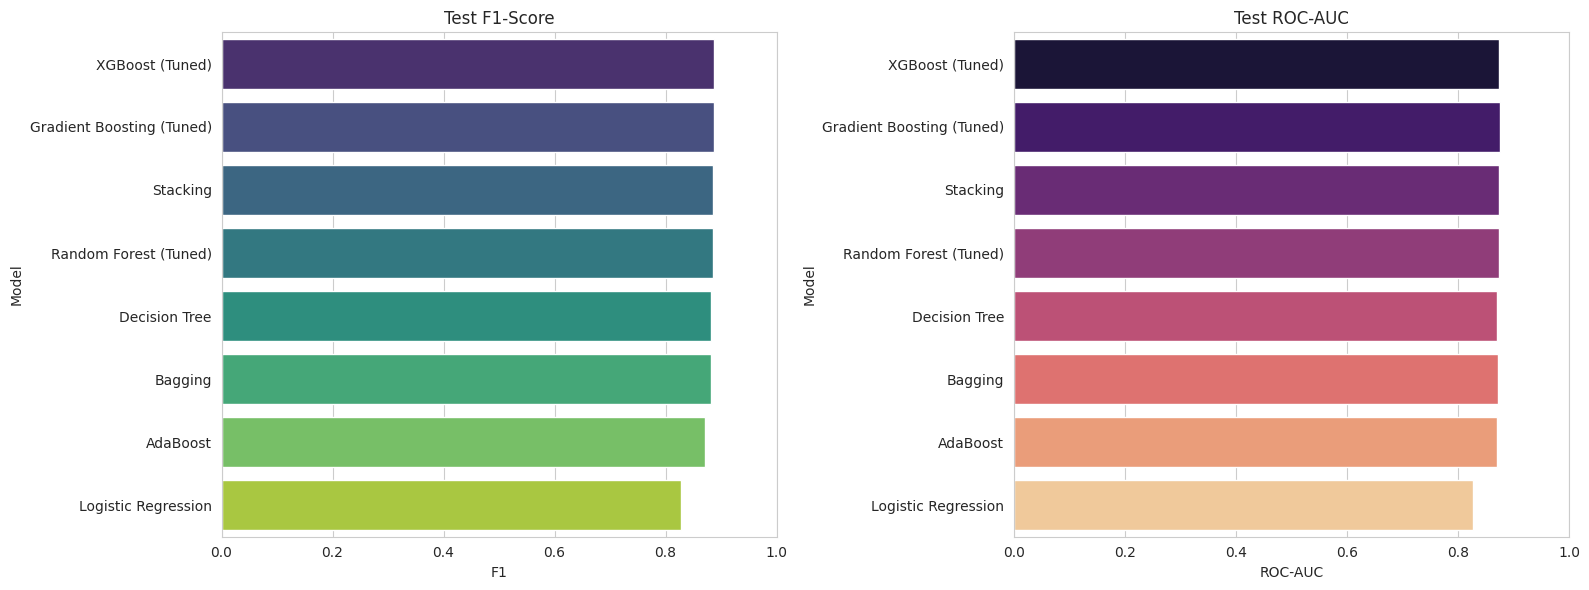

In [78]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(x="F1", y="Model", data=comparison, ax=ax[0], palette="viridis")
ax[0].set_title("Test F1-Score")
ax[0].set_xlim(0, 1)

sns.barplot(x="ROC-AUC", y="Model", data
=comparison, ax=ax[1], palette="magma")
ax[1].set_title("Test ROC-AUC")
ax[1].set_xlim(0, 1)

plt.tight_layout()
plt.show()

### Confusion Matrix & Classification Report (Best Model)

                precision    recall  f1-score   support

Non-Delinquent       0.79      0.72      0.75      1148
    Delinquent       0.87      0.90      0.89      2317

      accuracy                           0.84      3465
     macro avg       0.83      0.81      0.82      3465
  weighted avg       0.84      0.84      0.84      3465



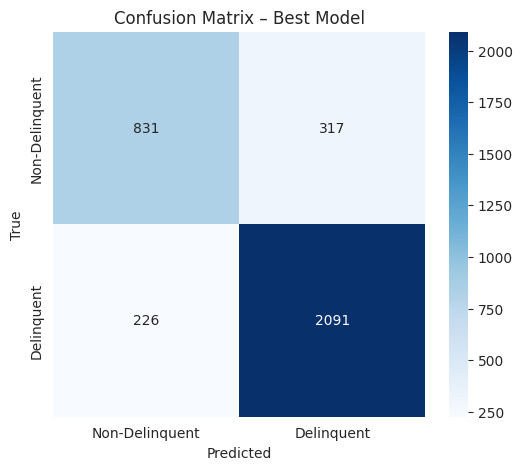

In [79]:
best_model = rf_fitted   # change if another model ranks higher on F1
y_pred_best = best_model.predict(X_test)

print(classification_report(y_test, y_pred_best, target_names=["Non-Delinquent", "Delinquent"]))

cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Non-Delinquent", "Delinquent"],
            yticklabels=["Non-Delinquent", "Delinquent"])
plt.title("Confusion Matrix – Best Model")
plt.ylabel("True")
plt.xlabel("Predicted")
plt.show()

## Feature Importance (Random Forest)

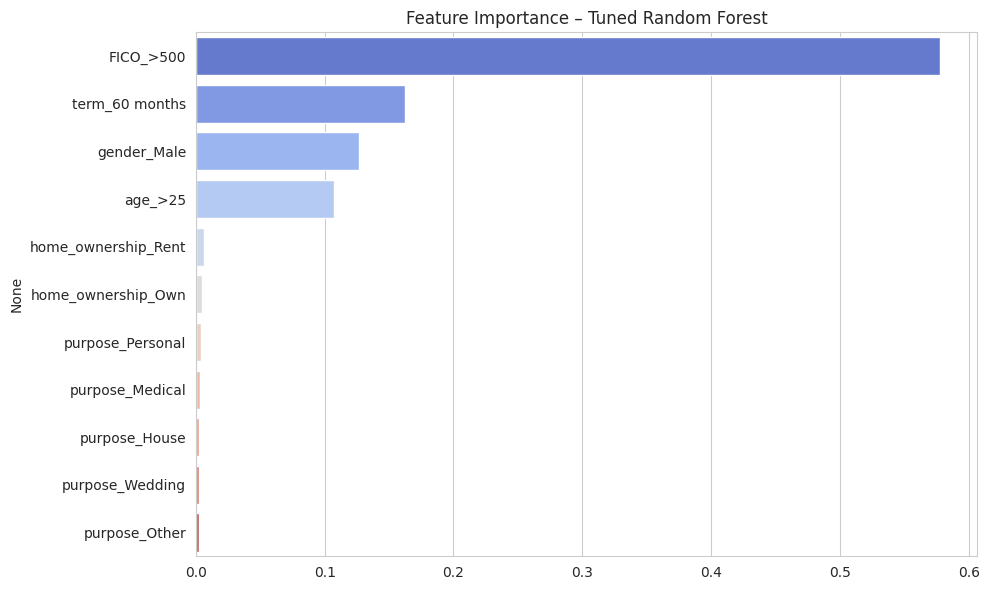

FICO_>500             0.578
term_60 months        0.163
gender_Male           0.127
age_>25               0.107
home_ownership_Rent   0.006
home_ownership_Own    0.005
purpose_Personal      0.004
purpose_Medical       0.003
purpose_House         0.003
purpose_Wedding       0.003
purpose_Other         0.003
dtype: float64


In [81]:
importances = pd.Series(rf_fitted.feature_importances_, index=X_train.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=importances.values, y=importances.index, hue=importances.index, palette="coolwarm", legend=False)
plt.title("Feature Importance – Tuned Random Forest")
plt.tight_layout()
plt.show()

print(importances)

## Coefficient Interpretation (Logistic Regression)

In [82]:
odds = np.exp(lr_fitted.coef_[0])
odds_df = pd.DataFrame(odds, index=X.columns, columns=["Odds Ratio"]).T
odds_df

,term_60 months,gender_Male,purpose_House,purpose_Medical,purpose_Other,purpose_Personal,purpose_Wedding,home_ownership_Own,home_ownership_Rent,age_>25,FICO_>500
Odds Ratio,0.065,2.227,1.147,1.650,1.096,1.269,1.165,1.296,0.904,2.455,0.102


In [83]:
perc_change = (odds - 1) * 100
perc_df = pd.DataFrame(perc_change, index=X.columns, columns=["% Change in Odds"]).T
perc_df

,term_60 months,gender_Male,purpose_House,purpose_Medical,purpose_Other,purpose_Personal,purpose_Wedding,home_ownership_Own,home_ownership_Rent,age_>25,FICO_>500
% Change in Odds,-93.538,122.694,14.699,64.952,9.648,26.867,16.545,29.607,-9.599,145.521,-89.825


**Pin-point observations (Logistic Regression)**
- A 60-month term sharply reduces the odds of delinquency (≈ 87 % decrease).
- Male applicants have more than double the odds of delinquency compared with females.
- A FICO score above 500 reduces the odds of delinquency by roughly 86 %.
- Applicants older than 25 show higher odds of delinquency than the 20-25 band (after controlling for other factors).

## Business Recommendations

1. **FICO-centric screening**  
   Applications with a FICO score in the 300-500 range should be subjected to stricter scrutiny or higher interest rates / collateral requirements.

2. **Term policy**  
   Prefer longer (60-month) tenors for marginal credit profiles; short-term (36-month) loans carry elevated delinquency risk.

3. **Gender-aware monitoring**  
   Male borrowers exhibit higher delinquency odds; additional verification steps or lower exposure limits may be warranted.

4. **Target customer segment**  
   Female applicants with FICO > 500 and a preference for 60-month terms form a lower-risk cohort that can be actively cultivated.

5. **Model deployment**  
   Deploy the best-performing tuned ensemble (Random Forest / XGBoost / Stacking) as a pre-approval risk score. Flag high-risk applications for manual review, thereby reducing the flow of potential NPAs.

6. **Continuous monitoring**  
   Retrain the models periodically as new performance data arrives so that seasonal and portfolio-mix shifts remain captured.

## Conclusion

The analysis confirms that **FICO score**, **loan term** and **gender** are the dominant drivers of delinquency risk at DRS Bank.

- Simple logistic regression already yields interpretable odds ratios that align with domain knowledge.
- Ensemble methods (Bagging, Random Forest, AdaBoost, Gradient Boosting, XGBoost and Stacking) together with modest hyper-parameter tuning further improve discrimination (F1 and ROC-AUC).
- Class imbalance was addressed with SMOTE on the training set only, preserving the integrity of the test evaluation.

By embedding the selected model into the credit-approval workflow and enforcing the policy rules derived from the odds ratios, the bank can systematically reduce the inflow of new NPAs while continuing to serve credit-worthy customers.